# Task 1 missing-value EDA

คำถาม: ค่าว่างเป็นเพดานของ Task 1 (README: แถวที่ข้อมูลครบได้ AUC 0.918 ส่วนแถวที่ว่าง 8 ช่องเหลือ 0.847) มี feature ไหนที่ถ้าว่างแล้ว OOF แย่ลงจริง และเติมค่าได้จาก feature อื่นโดยไม่ใช้ label บ้าง แบบเดียวกับที่ Task 3 เจอ (V9a, +0.0026)

ตอนนี้ `pis/task1_features.py` เติมค่าอยู่แล้ว 5 ตัว: `account_age_days`, `friend_network_size`, `level_progression_speed`, `level`, `reports_received`

ข้อมูล: แถว train ที่มี label (90,816 แถว) + OOF ของโมเดลปัจจุบัน (`outputs/experiments/task1_oof.csv` จาก `Task1/eda/make_oof.py`: StratifiedKFold 3, seed 342, 12 threads เหมือนตารางใน README) ไม่ใช้ test

Metric: **F2 ของคลาสคนโกง** (`fbeta_score(y, pred, beta=2)`, pos_label=1) ซึ่งเป็นตัวที่ Kaggle ใช้ให้คะแนน ไม่ใช่ macro F2 ที่ตารางใน README ใช้ threshold มาจาก `pis.tabular._threshold` ที่ตอนนี้หาค่าที่ทำให้ F2 ของคลาสคนโกงสูงสุด (commit 080d9a0)

## Imports

In [1]:
import json, os, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import PercentFormatter
from pathlib import Path
from scipy.cluster.hierarchy import fcluster, leaves_list, linkage
from scipy.spatial.distance import squareform
from scipy.stats import binom, norm, spearmanr
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import fbeta_score, r2_score, roc_auc_score
from sklearn.model_selection import KFold, StratifiedKFold

pd.set_option('display.width', 200)  # keep wide tables on one line instead of "..."

## Setup

In [2]:
# Find the repo root (the folder with `run.py`), move there and add it to `sys.path`, so paths like `outputs/...` and `import pis` work wherever the kernel started.
ROOT = Path.cwd().resolve()
while not (ROOT / 'run.py').exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError('run.py not found; open this notebook inside the repo')
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from pis.common import DEFAULT_DATA         # ../cpe342-kaggle-main, needs ROOT on sys.path
from pis.tabular import _threshold          # the pipeline's OOF threshold search for cheater-class F2
from pis.task1_features import IMPUTED      # the 5 features the pipeline already imputes

BLUE, RED, ORANGE, INK, GRID = '#2a78d6', '#e34948', '#eb6834', '#52514e', '#e5e4df'

def tidy(ax, grid='y'):
    ax.grid(axis=grid, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)

print(f"repo root: {ROOT}")

repo root: C:\Users\acer\Desktop\cpe342\project\player-intelligence-system-cpe342


## Load data & check the OOF

OOF ต้องเรียงแถวเดียวกับ `train.csv` หลังตัดแถวไม่มี label (เช็ค `player_id`) AUC ต้องได้ 0.8922 (ค่าที่รันได้ในเครื่องนี้) และ threshold กับ F2 (คนโกง) ต้องตรงกับที่ pipeline รายงานใน `task1_metrics.json` ของ run เดียวกัน

In [3]:
tr = pd.read_csv(DEFAULT_DATA / '01_binary_classification' / 'train.csv')
tr = tr.loc[tr['is_cheater'].notna()].reset_index(drop=True)  # the pipeline drops the 13,184 unlabelled rows
o = pd.read_csv('outputs/experiments/task1_oof.csv')           # current model, 3-fold OOF
assert (tr['player_id'].to_numpy() == o['player_id'].to_numpy()).all(), 'OOF row order differs from train.csv'
assert (tr['is_cheater'].to_numpy() == o['target'].to_numpy()).all()

feats = [c for c in tr.columns if c not in ('player_id', 'is_cheater')]  # the 31 raw features
y = o['target'].to_numpy().astype(int)
p = o['probability_1'].to_numpy()
threshold, f2_all = _threshold(y, p)   # same threshold the pipeline picks (maximises cheater-class F2)
pred = (p >= threshold).astype(int)
auc_all = roc_auc_score(y, p)
reported = json.loads(Path('outputs/experiments/task1_missing_eda_run/task1_metrics.json').read_text())  # same make_oof.py run
print(f"rows {len(tr):,} | cheaters {y.mean():.1%} | OOF AUC {auc_all:.4f} | threshold {threshold:.4f} | F2 (cheater) {f2_all:.4f} | "
      f"macro F2 at this threshold {fbeta_score(y, pred, beta=2, average='macro'):.4f}")
# README: AUC 0.8926 (macro-F2 tables); this laptop gives 0.8922 (environment difference, see the NOTE below).
assert abs(auc_all - 0.8922) < 2e-4, 'OOF AUC does not match the local reproduction (0.8922)'
assert reported['metric'] == 'f2_cheater_class', 'make_oof.py output predates the cheater-F2 threshold; re-run it'
assert abs(threshold - reported['threshold']) < 1e-12 and abs(f2_all - reported['oof_score']) < 1e-12, 'threshold / F2 differ from the pipeline'


def f2_cheater(tp, fp, fn):
    # F2 of the cheater class from confusion counts (works on arrays too).
    return 5 * tp / (5 * tp + 4 * fn + fp)


def scores(m):
    # AUC and cheater-class F2 at the current threshold on the rows in boolean mask m.
    t, q = y[m], pred[m]
    tp, fp, fn = np.sum((t == 1) & (q == 1)), np.sum((t == 0) & (q == 1)), np.sum((t == 1) & (q == 0))
    return roc_auc_score(t, p[m]), f2_cheater(tp, fp, fn)


assert abs(scores(np.ones(len(y), bool))[1] - fbeta_score(y, pred, beta=2)) < 1e-12

rows 90,816 | cheaters 34.9% | OOF AUC 0.8922 | threshold 0.1805 | F2 (cheater) 0.8381 | macro F2 at this threshold 0.7165


**NOTE:**


**Metric.** Kaggle scores Task 1 with F2 of the cheater class, not macro F2. The README tables (and the first version of this notebook) use macro F2. Since commit 080d9a0, `_threshold` maximises cheater-class F2. On these 3-fold OOF the threshold moves from 0.380 to 0.1805, F2 (cheater) is 0.8381, and macro F2 at that threshold falls to 0.7165. On Kaggle the same change (threshold 0.386 → ~0.18) took Main_baseline from 0.82343 to 0.83699. Every F2 below is cheater-class F2 at threshold 0.1805.

**AUC 0.8922 vs README 0.8926.** The difference is not in this script. The README's own command (`python Task1/experiments.py ../cpe342-kaggle-main margins+impute`) gives the same AUC 0.8922 on this laptop, and its baseline row shifts the same way (0.8881 vs 0.8883). 12 threads or all 16 give the same AUC. The README numbers come from another environment. The OOF probabilities do not depend on the threshold, and re-running `make_oof.py` after the rebase gives bit-identical probabilities.

## 1. Missingness overview

ค่าว่างต่อ feature (สีส้ม = 5 ตัวที่ pipeline เติมค่าอยู่แล้ว) และจำนวนช่องที่ว่างต่อแถว พร้อม AUC / F2 (คนโกง) ของ OOF ในแต่ละกลุ่ม

share missing per feature: min 0.6%, median 9.6%, max 24.3% | rows with no missing value: 1.8%, mean missing per row 3.71


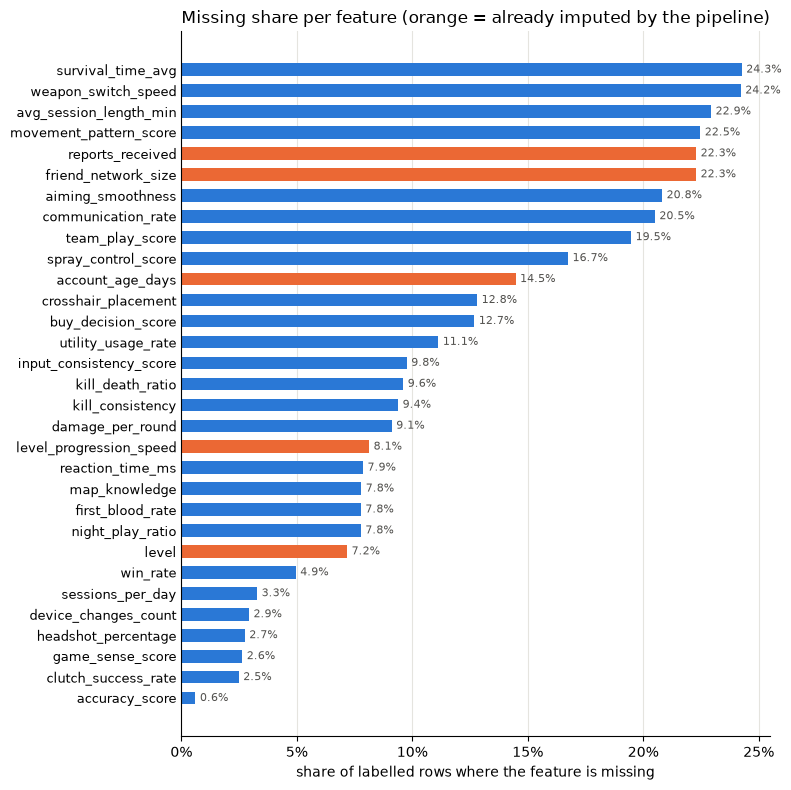

In [4]:
miss = tr[feats].isna()
share_missing = miss.mean().sort_values()
n_missing = miss.sum(axis=1).to_numpy()
print(f"share missing per feature: min {share_missing.min():.1%}, median {share_missing.median():.1%}, max {share_missing.max():.1%} | "
      f"rows with no missing value: {(n_missing == 0).mean():.1%}, mean missing per row {n_missing.mean():.2f}")

fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(share_missing.index, share_missing.values, height=0.6,
        color=[ORANGE if c in IMPUTED else BLUE for c in share_missing.index])
for name, v in share_missing.items():
    ax.text(v + 0.002, name, f"{v:.1%}", va='center', fontsize=8, color=INK)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel('share of labelled rows where the feature is missing')
ax.set_title('Missing share per feature (orange = already imputed by the pipeline)', loc='left')
ax.tick_params(axis='y', length=0, labelsize=9)
tidy(ax, 'x')
plt.tight_layout()
plt.show()

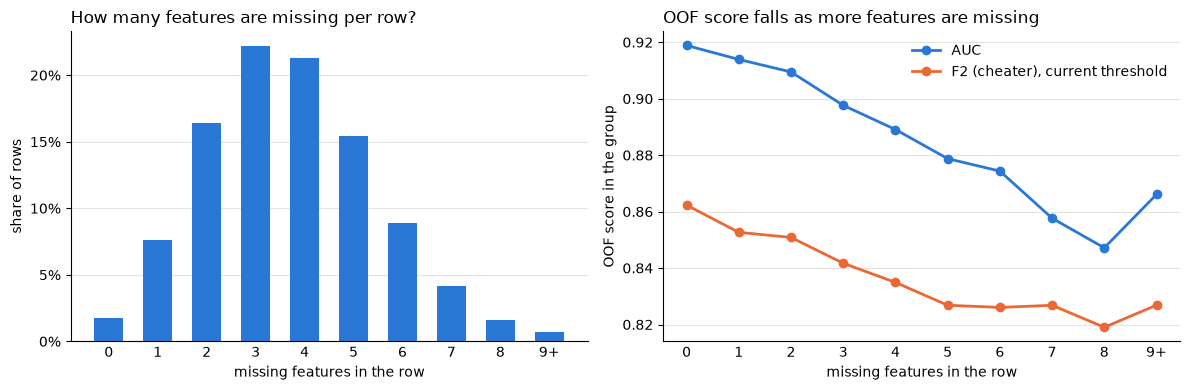

,rows,row_share,cheater_share,AUC,F2 (cheater)
missing features,,,,,
0,"1,607",1.8%,35.7%,0.9189,0.8623
1,"6,909",7.6%,34.5%,0.9139,0.8527
2,"14,880",16.4%,34.8%,0.9095,0.8508
3,"20,149",22.2%,35.0%,0.8976,0.8417
4,"19,335",21.3%,34.8%,0.8891,0.8349
5,"13,985",15.4%,34.5%,0.8788,0.8268
6,"8,080",8.9%,35.6%,0.8744,0.8261
7,"3,771",4.2%,36.1%,0.8577,0.8268
8,"1,434",1.6%,35.1%,0.8472,0.8190


In [5]:
group = np.minimum(n_missing, 9)
rows = []
for g in range(10):
    m = group == g
    auc, f2 = scores(m)
    rows.append({'missing features': '9+' if g == 9 else str(g), 'rows': int(m.sum()), 'row_share': m.mean(),
                 'cheater_share': y[m].mean(), 'AUC': auc, 'F2 (cheater)': f2})
by_count = pd.DataFrame(rows).set_index('missing features')

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.bar(by_count.index, by_count['row_share'], width=0.6, color=BLUE)
a1.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
a1.set_xlabel('missing features in the row'); a1.set_ylabel('share of rows')
a1.set_title('How many features are missing per row?', loc='left')
a1.tick_params(axis='x', length=0); tidy(a1)
a2.plot(by_count.index, by_count['AUC'], marker='o', color=BLUE, linewidth=2, label='AUC')
a2.plot(by_count.index, by_count['F2 (cheater)'], marker='o', color=ORANGE, linewidth=2, label='F2 (cheater), current threshold')
a2.set_xlabel('missing features in the row'); a2.set_ylabel('OOF score in the group')
a2.set_title('OOF score falls as more features are missing', loc='left')
a2.legend(frameon=False); a2.tick_params(axis='x', length=0); tidy(a2)
plt.tight_layout()
plt.show()

(by_count.style
    .format({'rows': '{:,}', 'row_share': '{:.1%}', 'cheater_share': '{:.1%}', 'AUC': '{:.4f}', 'F2 (cheater)': '{:.4f}'})
    .set_caption('OOF score by number of missing features per row'))

**NOTE:**


Only 1.8% of rows are complete. On average 3.7 of the 31 features are missing per row, and the share per feature ranges from 0.6% to 24%. The score falls with each missing feature: from 0 to 8 missing, AUC goes 0.919 → 0.847 and F2 (cheater) goes 0.862 → 0.819. F2 drops less than AUC and flattens from 5 missing on, because at threshold 0.18 almost every cheater is flagged anyway. The cheater share is the same in every group (34.5–36.1%), so the drop is lost information, not harder rows.

### 1b. One threshold for all rows, or one per missing-count group?

แถวที่ว่างมากความน่าจะเป็นของ OOF แยกคลาสได้แย่กว่า threshold ที่ดีที่สุดของแต่ละกลุ่มจึงอาจต่างกัน แบ่ง 4 กลุ่มตามจำนวนช่องที่ว่าง (0-2, 3-4, 5-6, 7+) แล้วหา threshold ที่ทำให้ F2 (คนโกง) ของกลุ่มนั้นสูงสุด

- **in-sample:** เลือกและวัดบน OOF ชุดเดียวกัน (มองในแง่ดีเกินจริง)
- **honest:** ใช้ fold ชุดเดียวกับ pipeline (StratifiedKFold 3, seed 342) เลือก threshold บน 2 fold แล้ววัดบน fold ที่ 3 เทียบกับ threshold เดียวทุกแถวที่เลือกแบบเดียวกัน

In [6]:
GROUPS = ['0-2', '3-4', '5-6', '7+']
grp = np.select([n_missing <= 2, n_missing <= 4, n_missing <= 6], GROUPS[:3], GROUPS[3])
rows = []
per_group_in = np.zeros(len(y), int)
for g in GROUPS:
    m = grp == g
    t_g, f_g = _threshold(y[m], p[m])
    per_group_in[m] = p[m] >= t_g
    rows.append({'group': g, 'rows': int(m.sum()), 'best threshold': t_g, 'F2 at best': f_g,
                 'F2 at global threshold': fbeta_score(y[m], pred[m], beta=2)})
by_group = pd.DataFrame(rows).set_index('group')
by_group['gain'] = by_group['F2 at best'] - by_group['F2 at global threshold']

folds = list(StratifiedKFold(n_splits=3, shuffle=True, random_state=342).split(np.zeros(len(y)), y))  # the pipeline's folds
honest_global, honest_group = np.zeros(len(y), int), np.zeros(len(y), int)
for a, b in folds:
    honest_global[b] = p[b] >= _threshold(y[a], p[a])[0]
    for g in GROUPS:
        ga, gb = a[grp[a] == g], b[grp[b] == g]
        honest_group[gb] = p[gb] >= _threshold(y[ga], p[ga])[0]
summary_1b = pd.Series({'one threshold, in-sample': f2_all, 'per group, in-sample': fbeta_score(y, per_group_in, beta=2),
                        'one threshold, honest': fbeta_score(y, honest_global, beta=2),
                        'per group, honest': fbeta_score(y, honest_group, beta=2)}, name='F2 (cheater)')
print(' | '.join(f"{k} {v:.4f}" for k, v in summary_1b.items()))
print(f"per group vs one threshold, honest: {summary_1b['per group, honest'] - summary_1b['one threshold, honest']:+.4f}")
(by_group.style
    .format({'rows': '{:,}', 'best threshold': '{:.3f}', 'F2 at best': '{:.4f}', 'F2 at global threshold': '{:.4f}', 'gain': '{:+.4f}'})
    .set_caption(f'Best threshold per missing-count group (in-sample; global threshold {threshold:.3f})'))

one threshold, in-sample 0.8381 | per group, in-sample 0.8385 | one threshold, honest 0.8377 | per group, honest 0.8381
per group vs one threshold, honest: +0.0004


,rows,best threshold,F2 at best,F2 at global threshold,gain
group,,,,,
0-2,"23,396",0.186,0.8526,0.8522,+0.0005
3-4,"39,484",0.180,0.8385,0.8384,+0.0001
5-6,"22,065",0.159,0.8276,0.8265,+0.0011
7+,"5,871",0.184,0.8255,0.8249,+0.0006


**NOTE:**


One threshold is enough. The best threshold per group stays between 0.159 and 0.186, close to the global 0.181. Per-group thresholds gain +0.0004 in-sample. In the honest version (choose on 2 folds, score on the 3rd) they also gain +0.0004: 0.8381 vs 0.8377 for one threshold. That is below the 3-fold noise and far below +0.002, as the README found for macro F2.

## 2. Score by feature: missing vs present (+ random-group null)

แต่ละ feature แบ่งแถวเป็น "ว่าง" กับ "มีค่า" แล้วเทียบ AUC และ F2 (คนโกง, threshold ของ pipeline) ของ OOF รวมทั้ง % คนโกงในสองกลุ่ม (ดูว่าการว่างบอก label หรือไม่)

กลุ่มที่ว่างมีขนาดต่างกัน (0.6% ถึง 24% ของแถว) คะแนนกลุ่มเล็กจึงแกว่งได้มาก เลยเทียบกับกลุ่มที่สุ่มมาจากทุกแถวด้วยขนาดเท่ากัน 2,000 ครั้ง:
- `z` = (คะแนนกลุ่มที่ว่าง − ค่าเฉลี่ยของกลุ่มสุ่ม) / SD ของกลุ่มสุ่ม: ติดลบ = แย่กว่ากลุ่มสุ่ม
- `p` = two-sided p-value จาก 2,000 ครั้ง (ต่ำสุดที่วัดได้ ≈ 0.001)
- ทดสอบ 31 feature พร้อมกัน จึงใช้ Bonferroni: significant เมื่อ p < 0.05 / 31 = 0.0016 (คือไม่มีกลุ่มสุ่มไหนแย่ขนาดนั้นเลย)
- AUC เป็นตัวทดสอบหลัก เพราะไม่ขึ้นกับสัดส่วนคนโกงในกลุ่ม ส่วน F2 ขึ้นกับสัดส่วนนั้นด้วย

In [7]:
rows = []
for c in feats:
    m = miss[c].to_numpy()
    auc_m, f2_m = scores(m)
    auc_p, f2_p = scores(~m)
    rows.append({'feature': c, 'rows_missing': int(m.sum()), 'row_share': m.mean(),
                 'cheat_missing': y[m].mean(), 'cheat_present': y[~m].mean(),
                 'auc_missing': auc_m, 'auc_present': auc_p, 'f2_missing': f2_m, 'f2_present': f2_p})
by_feat = pd.DataFrame(rows).set_index('feature')
by_feat['auc_gap'] = by_feat['auc_missing'] - by_feat['auc_present']
by_feat['f2_gap'] = by_feat['f2_missing'] - by_feat['f2_present']

# Null: random groups of the same size. Rows are sorted by p once, so a group's AUC comes from rank sums (fast).
D = 2000
rng = np.random.default_rng(342)
order = np.argsort(p, kind='stable')
ys, preds_s = y[order], pred[order]
sizes = by_feat['rows_missing'].to_numpy()
null_auc = np.empty((D, len(feats)))
null_f2 = np.empty((D, len(feats)))
for d in range(D):
    rank = rng.permutation(len(y))  # one random ordering per draw; a group of size n is its first n rows
    for j, n in enumerate(sizes):
        m = rank < n
        r = np.cumsum(m)            # 1-based rank of each chosen row inside the group
        pos = m & (ys == 1)
        n1 = pos.sum(); n0 = n - n1
        null_auc[d, j] = (r[pos].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)
        tp = np.sum(pos & (preds_s == 1)); fp = np.sum(m & (ys == 0) & (preds_s == 1))
        null_f2[d, j] = f2_cheater(tp, fp, n1 - tp)
    if d == 0:  # check the fast AUC against sklearn on the first draw
        chosen = np.zeros(len(y), bool); chosen[order[rank < sizes[0]]] = True
        assert abs(null_auc[0, 0] - roc_auc_score(y[chosen], p[chosen])) < 1e-6


def null_test(obs, null):
    low = (1 + (null <= obs).sum(0)) / (D + 1)
    high = (1 + (null >= obs).sum(0)) / (D + 1)
    return np.minimum(1, 2 * np.minimum(low, high)), (obs - null.mean(0)) / null.std(0)


by_feat['p_auc'], by_feat['z_auc'] = null_test(by_feat['auc_missing'].to_numpy(), null_auc)
by_feat['p_f2'], by_feat['z_f2'] = null_test(by_feat['f2_missing'].to_numpy(), null_f2)
BONF = 0.05 / len(feats)
by_feat['sig_auc'] = np.where(by_feat['p_auc'] < BONF, np.where(by_feat['z_auc'] < 0, 'worse', 'better'), '')
by_feat['sig_f2'] = np.where(by_feat['p_f2'] < BONF, np.where(by_feat['z_f2'] < 0, 'worse', 'better'), '')
by_feat = by_feat.sort_values('z_auc')

k95 = int(binom.ppf(0.95, len(feats), 0.05))
print(f"p < 0.05 (no correction): AUC {(by_feat['p_auc'] < 0.05).sum()}, F2 {(by_feat['p_f2'] < 0.05).sum()} of {len(feats)} features | "
      f"chance alone: {len(feats) * 0.05:.1f} expected, up to {k95} in 95% of cases")
print(f"Bonferroni p < {BONF:.4f}: AUC worse {(by_feat['sig_auc'] == 'worse').sum()}, better {(by_feat['sig_auc'] == 'better').sum()} | "
      f"F2 worse {(by_feat['sig_f2'] == 'worse').sum()}, better {(by_feat['sig_f2'] == 'better').sum()} (chance alone: {len(feats) * BONF:.2f})")

(by_feat.drop(columns=['auc_present', 'f2_present']).style
    .format({'rows_missing': '{:,}', 'row_share': '{:.1%}', 'cheat_missing': '{:.1%}', 'cheat_present': '{:.1%}',
             'auc_missing': '{:.4f}', 'f2_missing': '{:.4f}', 'auc_gap': '{:+.4f}', 'f2_gap': '{:+.4f}',
             'p_auc': '{:.4f}', 'z_auc': '{:+.1f}', 'p_f2': '{:.4f}', 'z_f2': '{:+.1f}'})
    .bar(subset='z_auc', align=0, color=[RED, BLUE])
    .set_caption(f'OOF score where each feature is missing vs present (f2 = F2 of the cheater class at threshold {threshold:.3f}; '
                 f'AUC present ≈ {by_feat.auc_present.median():.4f}), sorted by z (AUC)'))

p < 0.05 (no correction): AUC 6, F2 6 of 31 features | chance alone: 1.6 expected, up to 4 in 95% of cases
Bonferroni p < 0.0016: AUC worse 4, better 0 | F2 worse 4, better 0 (chance alone: 0.05)


,rows_missing,row_share,cheat_missing,cheat_present,auc_missing,f2_missing,auc_gap,f2_gap,p_auc,z_auc,p_f2,z_f2,sig_auc,sig_f2
feature,,,,,,,,,,,,,,
reports_received,"20,242",22.3%,34.8%,35.0%,0.8538,0.8120,-0.0482,-0.0338,0.0010,-20.6,0.0010,-11.9,worse,worse
friend_network_size,"20,240",22.3%,34.8%,35.0%,0.8551,0.8163,-0.0467,-0.0281,0.0010,-19.9,0.0010,-9.9,worse,worse
account_age_days,"13,141",14.5%,34.7%,35.0%,0.8584,0.8145,-0.0390,-0.0277,0.0010,-13.9,0.0010,-8.3,worse,worse
crosshair_placement,"11,629",12.8%,35.1%,34.9%,0.8600,0.8210,-0.0366,-0.0196,0.0010,-12.2,0.0010,-5.6,worse,worse
level,"6,515",7.2%,34.9%,34.9%,0.8825,0.8332,-0.0104,-0.0052,0.0070,-2.7,0.2679,-1.1,,
game_sense_score,"2,393",2.6%,33.9%,35.0%,0.8759,0.8201,-0.0167,-0.0185,0.0120,-2.6,0.0130,-2.5,,
sessions_per_day,"2,976",3.3%,34.6%,34.9%,0.8833,0.8375,-0.0092,-0.0006,0.1249,-1.6,0.9125,-0.1,,
survival_time_avg,"22,034",24.3%,35.1%,34.9%,0.8901,0.8374,-0.0028,-0.0009,0.2199,-1.2,0.7106,-0.3,,
kill_death_ratio,"8,723",9.6%,34.7%,35.0%,0.8887,0.8349,-0.0039,-0.0035,0.2679,-1.1,0.3738,-0.9,,


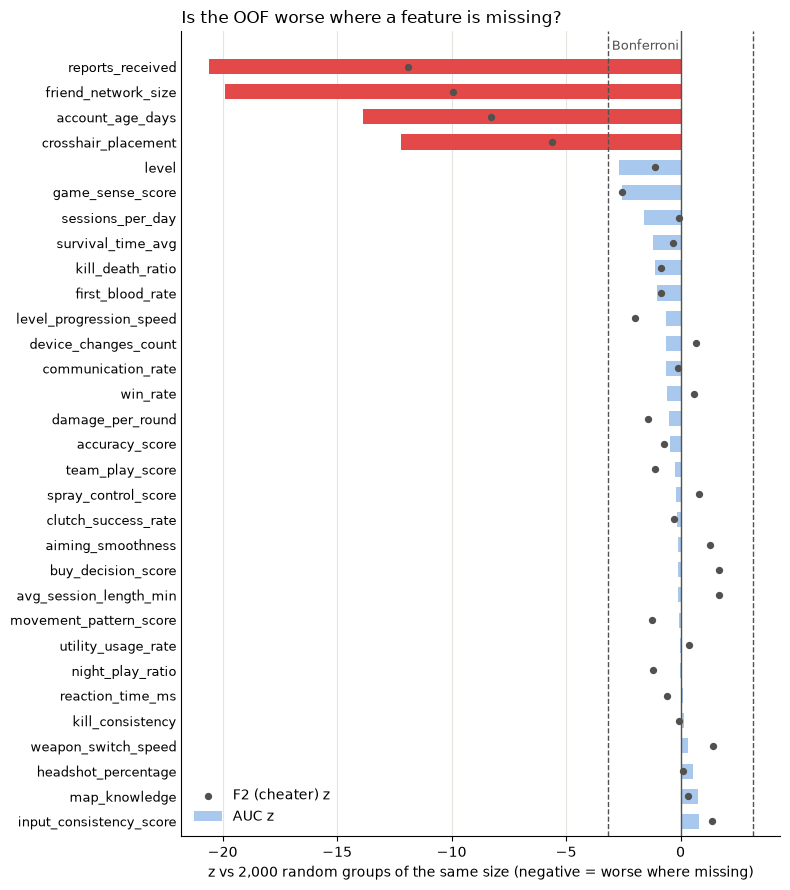

In [8]:
zz = by_feat.sort_values('z_auc', ascending=False)  # barh draws bottom-up, so the most negative ends on top
z_bonf = norm.ppf(1 - BONF / 2)
fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(zz.index, zz['z_auc'], height=0.6, color=[RED if s == 'worse' else BLUE if s == 'better' else '#a9c8ee' for s in zz['sig_auc']],
        label='AUC z')
ax.scatter(zz['z_f2'], zz.index, color=INK, s=18, zorder=3, label='F2 (cheater) z')
for v in (-z_bonf, z_bonf):
    ax.axvline(v, color=INK, linestyle='--', linewidth=1)
ax.axvline(0, color=INK, linewidth=1)
ax.set_ylim(-0.6, len(zz) + 0.4)
ax.text(-z_bonf + 0.15, len(zz) - 0.45, 'Bonferroni', ha='left', va='bottom', fontsize=9, color=INK)
ax.set_xlabel('z vs 2,000 random groups of the same size (negative = worse where missing)')
ax.set_title('Is the OOF worse where a feature is missing?', loc='left')
ax.legend(frameon=False, loc='lower left')
ax.tick_params(axis='y', length=0, labelsize=9)
tidy(ax, 'x')
plt.tight_layout()
plt.show()

**NOTE:**


Only 4 of 31 features have a real gap, and it is large: `reports_received`, `friend_network_size`, `account_age_days`, `crosshair_placement` (AUC z −12 to −21, F2 z −5.6 to −11.9; no random group came close). Their missing rows score AUC 0.854–0.860 against 0.892 where present, and F2 0.812–0.821 against about 0.84. All 4 are range-rule features, whose value can settle the label when present.

Without correction 6 features reach p < 0.05 on AUC, while chance alone gives up to 4. `level` (AUC p 0.007, F2 p 0.27) and `game_sense_score` (p 0.012 / 0.013) are borderline and not counted. The other 25 features cost nothing when missing, including `survival_time_avg` and `weapon_switch_speed`, which are missing in 24% of rows. The cheater share is the same whether a feature is missing or not (34–36%), so the fact that a value is missing carries no label information. The same 4 features are significant as under macro F2.

## 3. Can each feature be imputed? (label-free)

แต่ละ feature: เทรน HistGradientBoosting 3-fold บนแถวที่มีค่า ใช้ feature อื่น 30 ตัวเท่านั้น (**ไม่ใช้** `is_cheater` และไม่ใช้แถว test) แล้ววัด R² และ Spearman ระหว่างค่าที่ทายกับค่าจริงแบบ out-of-fold ทุก feature เป็นตัวเลข (ไม่มี feature binary) จึงใช้ R² ทั้งหมด

feature ที่ช่วยทายวัดด้วย permutation importance (R² ที่หายไปเมื่อสลับค่า feature นั้น, 5,000 แถวของ fold สุดท้าย)

บาง feature หางยาวมาก (เช่น `level_progression_speed` 0.003 ถึง 80) R² บนค่าจริงจึงขึ้นกับค่าสุดขั้วไม่กี่แถว เลยเพิ่ม `R² (log1p)`: โมเดลเดียวกัน แต่เทรนและวัดบน log1p ของค่า (ทุก feature ไม่ติดลบ จึงคำนวณได้ทุกตัว)

เกณฑ์ "เติมค่าได้" = R² > 0.3 บนค่าจริง (เกณฑ์เดียวกับ Task 3) ถ้า log1p ทำให้ feature ข้ามเส้น 0.3 จะบอกไว้ใน NOTE ส่วน `imputed` = pipeline เติมค่าอยู่แล้ว (ใช้ `max_iter=200` ต่างจากที่นี่เล็กน้อย)

In [9]:
impute_rows = []
for f in feats:
    present = tr[f].notna()
    X = tr.loc[present, [c for c in feats if c != f]]  # the other 30 features only, never the label
    t = tr.loc[present, f]
    pr = np.zeros(len(t))
    for a, b in KFold(3, shuffle=True, random_state=342).split(X):
        model = HistGradientBoostingRegressor(random_state=342).fit(X.iloc[a], t.iloc[a])
        pr[b] = model.predict(X.iloc[b])
    pi = permutation_importance(model, X.iloc[b][:5000], t.iloc[b][:5000], n_repeats=3, random_state=342, scoring='r2')
    top = pd.Series(pi.importances_mean, X.columns).sort_values(ascending=False).head(3)
    r2_log = np.nan
    if t.min() >= 0:  # same model fit and scored on log1p(target), so a few extreme values do not dominate
        tl, pl = np.log1p(t), np.zeros(len(t))
        for a, b in KFold(3, shuffle=True, random_state=342).split(X):
            pl[b] = HistGradientBoostingRegressor(random_state=342).fit(X.iloc[a], tl.iloc[a]).predict(X.iloc[b])
        r2_log = r2_score(tl, pl)
    impute_rows.append({'feature': f, 'rows used': len(t), 'R²': r2_score(t, pr), 'R² (log1p)': r2_log, 'Spearman': spearmanr(t, pr)[0],
                        'imputed': 'yes' if f in IMPUTED else '',
                        'top predictors (R² drop)': ', '.join(f"{k} {v:.2f}" for k, v in top.items())})
imputation = pd.DataFrame(impute_rows).set_index('feature').sort_values('R²', ascending=False)
crossed = imputation[(imputation['R²'] > 0.3) != (imputation['R² (log1p)'] > 0.3)].index.tolist()
differ = imputation[(imputation['R² (log1p)'] - imputation['R²']).abs() > 0.05].index.tolist()
print(f"features with R² > 0.3: {(imputation['R²'] > 0.3).sum()} of {len(feats)} (log1p: {(imputation['R² (log1p)'] > 0.3).sum()}) | "
      f"on a different side of 0.3 with log1p: {crossed or 'none'} | |log1p − raw| > 0.05: {differ or 'none'}")
(imputation.style
    .format({'rows used': '{:,}', 'R²': '{:.3f}', 'R² (log1p)': '{:.3f}', 'Spearman': '{:.3f}'}, na_rep='–')
    .bar(subset='R²', color='#86b6ef', vmin=0, vmax=1)
    .set_caption('Label-free imputation, 3-fold out-of-fold on rows where the feature is present'))

features with R² > 0.3: 3 of 31 (log1p: 3) | on a different side of 0.3 with log1p: none | |log1p − raw| > 0.05: ['account_age_days', 'level_progression_speed', 'friend_network_size']


,rows used,R²,R² (log1p),Spearman,imputed,top predictors (R² drop)
feature,,,,,,
account_age_days,"77,675",0.709,0.865,0.848,yes,"level_progression_speed 0.99, friend_network_size 0.18, level 0.12"
level_progression_speed,"83,437",0.629,0.809,0.775,yes,"account_age_days 1.38, level 0.13, friend_network_size 0.03"
friend_network_size,"70,576",0.498,0.628,0.637,yes,"account_age_days 0.56, level_progression_speed 0.28, reports_received 0.06"
level,"84,301",0.286,0.287,0.512,yes,"level_progression_speed 1.02, account_age_days 0.60, friend_network_size 0.02"
reaction_time_ms,"83,675",0.235,0.193,0.404,,"input_consistency_score 0.13, aiming_smoothness 0.11, first_blood_rate 0.05"
spray_control_score,"75,612",0.209,0.213,0.404,,"aiming_smoothness 0.17, movement_pattern_score 0.11, reaction_time_ms 0.04"
aiming_smoothness,"71,914",0.208,0.214,0.383,,"spray_control_score 0.17, reaction_time_ms 0.13, input_consistency_score 0.01"
reports_received,"70,574",0.205,0.159,0.338,yes,"friend_network_size 0.19, account_age_days 0.12, crosshair_placement 0.03"
kill_death_ratio,"82,093",0.119,0.111,0.299,,"headshot_percentage 0.06, win_rate 0.04, accuracy_score 0.03"


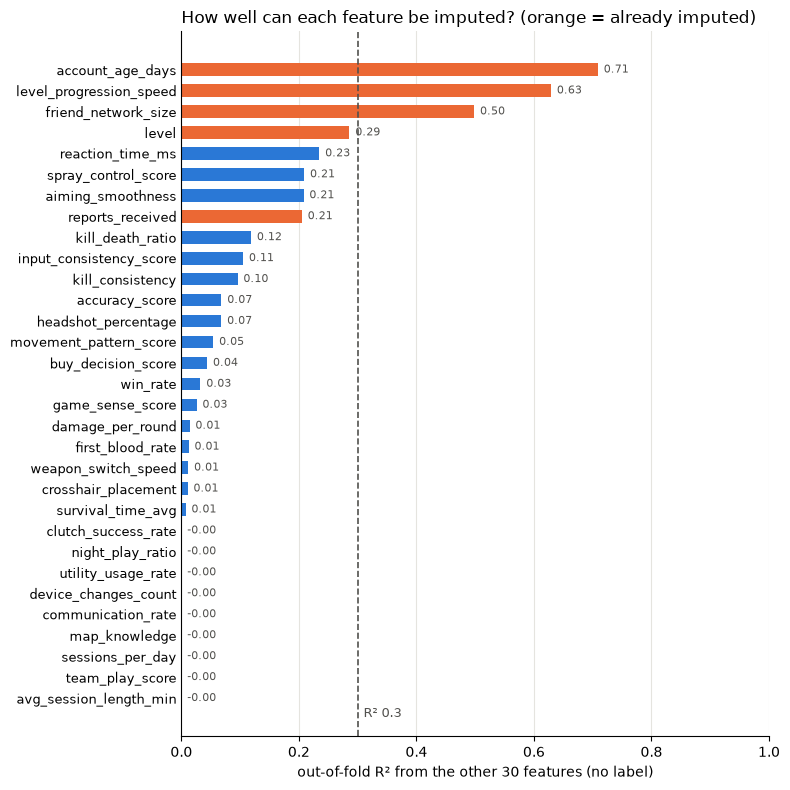

In [10]:
r2 = imputation['R²'].sort_values()
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(r2.index, r2.values.clip(min=0), height=0.6, color=[ORANGE if c in IMPUTED else BLUE for c in r2.index])
ax.axvline(0.3, color=INK, linestyle='--', linewidth=1.2)
ax.text(0.31, -0.9, 'R² 0.3', fontsize=9, color=INK)
for name, v in r2.items():
    ax.text(max(v, 0) + 0.01, name, f"{v:.2f}", va='center', fontsize=8, color=INK)
ax.set_xlim(0, 1)
ax.set_xlabel('out-of-fold R² from the other 30 features (no label)')
ax.set_title('How well can each feature be imputed? (orange = already imputed)', loc='left')
ax.tick_params(axis='y', length=0, labelsize=9)
tidy(ax, 'x')
plt.tight_layout()
plt.show()

**NOTE:**


Only one block is imputable: the account history. `account_age_days` R² 0.71, `level_progression_speed` 0.63 and `friend_network_size` 0.50 are predicted mostly from each other, and all three are already imputed. `level` (0.29) and `reports_received` (0.21) are below the 0.3 bar, and the pipeline imputes them too.

On the log scale the account block is more imputable than raw R² shows, because a few extreme values drive the raw number:

| feature | R² | R² (log1p) | Spearman |
|---|---|---|---|
| `level_progression_speed` | 0.63 | 0.81 | 0.78 |
| `account_age_days` | 0.71 | 0.87 | 0.85 |
| `friend_network_size` | 0.50 | 0.63 | 0.64 |

All three are already imputed. The other way round, `reports_received` (0.21 raw vs 0.16 log1p, Spearman 0.34) and `reaction_time_ms` (0.24 vs 0.19) are lower on the log scale. No feature crosses the 0.3 line with log1p, so the rule stays on raw R² and the shortlist does not change.

A second weak block, `reaction_time_ms` / `spray_control_score` / `aiming_smoothness` (R² 0.21–0.24), has no score gap. 17 features have R² < 0.05, and 10 of them are at 0 (nothing in the other features predicts them). `crosshair_placement`, the only significant feature that is not imputed, has R² 0.01.

## 4. Correlation blocks

Spearman ระหว่าง feature ทุกคู่ (pairwise บนแถวที่มีค่าทั้งคู่) เรียงด้วย hierarchical clustering (average linkage, ระยะ = 1 − |ρ|) feature ที่สัมพันธ์กันจะอยู่ติดกันเป็นบล็อก ถ้า feature อยู่ในบล็อกก็เติมค่าได้ ถ้าอยู่เดี่ยวๆ ก็เติมไม่ได้

ต่อด้วยคู่ที่สัมพันธ์กันมากที่สุด แยกตามคลาส (README: ในกลุ่มผู้เล่นปกติบางคู่สัมพันธ์กัน แต่ในกลุ่มคนโกงไม่)

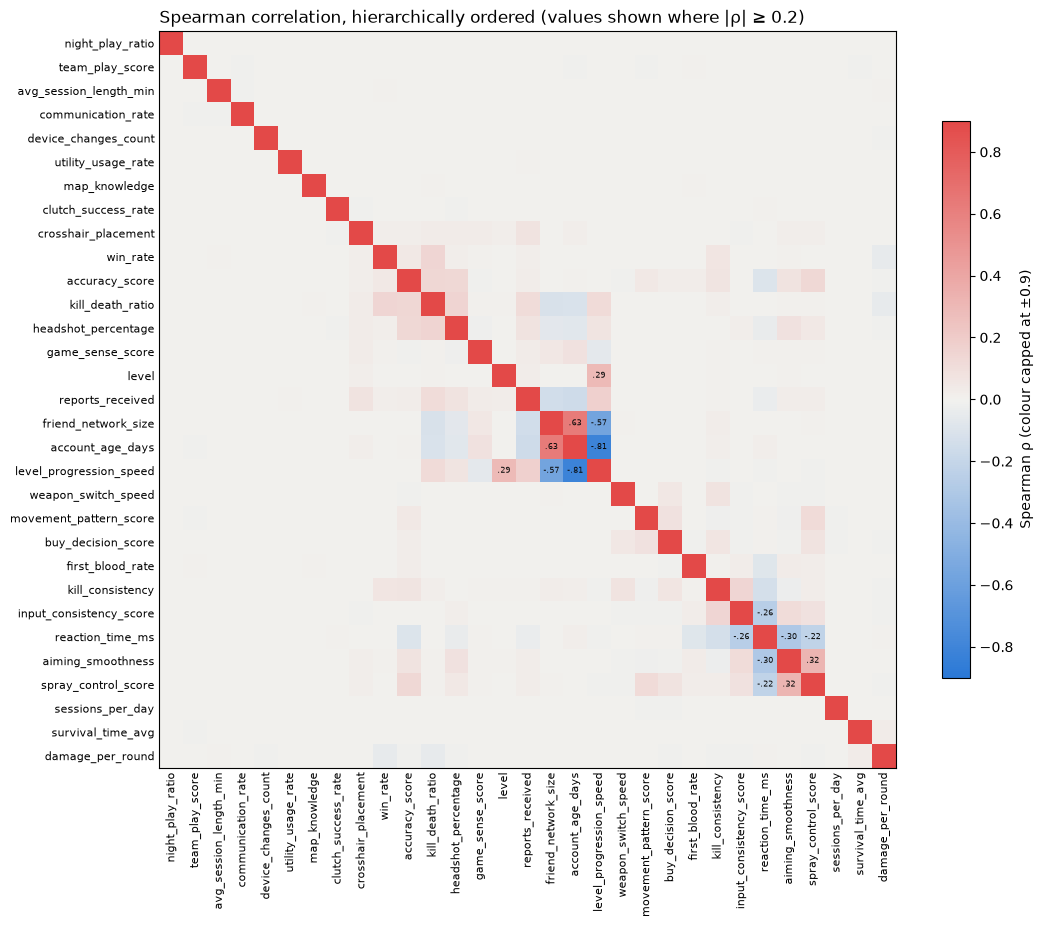

max |ρ| between two different features: 0.814 | pairs with |ρ| ≥ 0.2: 8 of 465
blocks with more than one feature (average-linkage, cut at 1 − |ρ| = 0.8):
   account_age_days, level_progression_speed, friend_network_size
   reaction_time_ms, aiming_smoothness, spray_control_score


In [11]:
rho = tr[feats].corr(method='spearman')
Z = linkage(squareform(1 - rho.abs().to_numpy(), checks=False), 'average')
ordered = rho.index[leaves_list(Z)]
R = rho.loc[ordered, ordered]
off = np.abs(R.to_numpy()[~np.eye(len(R), dtype=bool)])
vmax = np.ceil(off.max() * 10) / 10

cmap = LinearSegmentedColormap.from_list('div', [BLUE, '#f2f1ee', RED])
fig, ax = plt.subplots(figsize=(11, 9.5))
im = ax.imshow(R.to_numpy(), cmap=cmap, vmin=-vmax, vmax=vmax)
for i in range(len(R)):
    for j in range(len(R)):
        v = R.iat[i, j]
        if i != j and abs(v) >= 0.2:
            ax.text(j, i, f"{v:.2f}".replace('0.', '.'), ha='center', va='center', fontsize=6, color='#0b0b0b')
ax.set_xticks(range(len(R)), R.index, rotation=90, fontsize=8)
ax.set_yticks(range(len(R)), R.index, fontsize=8)
ax.tick_params(length=0)
fig.colorbar(im, ax=ax, shrink=0.7, label='Spearman ρ (colour capped at ±%.1f)' % vmax)
ax.set_title('Spearman correlation, hierarchically ordered (values shown where |ρ| ≥ 0.2)', loc='left')
plt.tight_layout()
plt.show()

blocks = pd.Series(fcluster(Z, t=0.8, criterion='distance'), rho.index)  # same block if linked at |ρ| ≥ ~0.2
blocks = blocks.groupby(blocks).apply(lambda s: list(s.index))
print(f"max |ρ| between two different features: {off.max():.3f} | pairs with |ρ| ≥ 0.2: {int((off >= 0.2).sum() / 2)} of {len(feats) * (len(feats) - 1) // 2}")
print('blocks with more than one feature (average-linkage, cut at 1 − |ρ| = 0.8):')
for b in blocks[blocks.map(len) > 1]:
    print('  ', ', '.join(b))

In [12]:
pairs = rho.where(np.triu(np.ones(rho.shape, bool), 1)).stack().rename('all rows').to_frame()
pairs = pairs.reindex(pairs['all rows'].abs().sort_values(ascending=False).index).head(12)
for k, name in ((0, 'legit only'), (1, 'cheaters only')):
    r_k = tr.loc[y == k, feats].corr(method='spearman')
    pairs[name] = [r_k.loc[a, b] for a, b in pairs.index]
pairs.style.format('{:+.3f}').set_caption('Strongest pairs: Spearman ρ over all rows and inside each class')

**NOTE:**


There are two blocks: account history (age, progression speed, friends; |ρ| 0.57–0.81) and aim mechanics (reaction time, aiming smoothness, spray control, input consistency; |ρ| 0.22–0.32). Only 8 of 465 pairs reach |ρ| 0.2; everything else is independent. The blocks look the same in both classes. The only pairs that depend on the class are `reports_received` with age and progression speed (ρ ≈ ∓0.28 for legit players, 0.00 for cheaters), as the README found.

## 5. Shortlist & oracle

**Shortlist** = gap ที่ significant (AUC แย่กว่ากลุ่มสุ่ม, Bonferroni) **และ** เติมค่าได้ (R² > 0.3) **และ** ยังไม่ได้เติมค่าใน pipeline

**Oracle** (ขอบบน): แถวที่ feature นั้นว่างให้ได้คุณภาพเท่ากลุ่มที่มีค่า ทำโดยแทนความน่าจะเป็น OOF ของแถวที่ว่างด้วยค่าที่สุ่มจากแถวที่มีค่า**ในคลาสเดียวกัน** (คนโกงสุ่มจากคนโกง ผู้เล่นปกติสุ่มจากผู้เล่นปกติ) แล้ววัด AUC และ F2 (คนโกง) ทั้งหมดใหม่ ทั้งที่ threshold เดิมและเลือก threshold ใหม่ (retuned) (เฉลี่ย 10 รอบ) การเติมค่าจริงทำได้ไม่ถึงขอบบนนี้ เพราะค่าที่เติมไม่ใช่ค่าจริง และโมเดลเห็น feature ที่ใช้ทายอยู่แล้ว

ทำ oracle ทุก feature (ไม่ใช่แค่ shortlist) เพื่อดูว่าค่าว่างของแต่ละตัวมีผลแค่ไหน และทำแบบรวม: ถ้าทุกแถวได้คุณภาพเท่าแถวที่ว่างไม่เกิน 1 ช่อง

In [13]:
def oracle(target_rows, source_rows, reps=10, seed=342):
    # Rows in target_rows get OOF probabilities drawn from source_rows of the same class; returns mean scores.
    rng = np.random.default_rng(seed)
    out = []
    for _ in range(reps):
        q = p.copy()
        for k in (0, 1):
            t, s = target_rows & (y == k), source_rows & (y == k)
            q[t] = rng.choice(p[s], t.sum())
        out.append((roc_auc_score(y, q), fbeta_score(y, q >= threshold, beta=2), _threshold(y, q)[1]))
    return np.mean(out, axis=0)


orc = pd.DataFrame([oracle(miss[f].to_numpy(), ~miss[f].to_numpy()) for f in feats], index=feats,
                   columns=['AUC oracle', 'F2 oracle', 'F2 oracle (retuned)'])
orc['ΔAUC'] = orc['AUC oracle'] - auc_all
orc['ΔF2'] = orc['F2 oracle'] - f2_all
orc['ΔF2 (retuned)'] = orc['F2 oracle (retuned)'] - f2_all

table = by_feat[['row_share', 'auc_gap', 'z_auc', 'sig_auc']].join(imputation[['R²', 'imputed']]).join(orc[['ΔAUC', 'ΔF2', 'ΔF2 (retuned)']])
table['significant'] = table['sig_auc'] == 'worse'
table['imputable'] = table['R²'] > 0.3
table['shortlist'] = table['significant'] & table['imputable'] & (table['imputed'] == '')
table = table.drop(columns='sig_auc').sort_values('ΔF2', ascending=False)

total = oracle(n_missing >= 2, n_missing <= 1)
print(f"all-missingness oracle (rows with 2+ missing scored like rows with 0-1 missing): "
      f"AUC {total[0]:.4f} ({total[0] - auc_all:+.4f}) | F2 (cheater) {total[1]:.4f} ({total[1] - f2_all:+.4f}), retuned {total[2] - f2_all:+.4f}")
print(f"shortlist: {list(table.index[table['shortlist']]) or 'empty'}")

(table.style
    .format({'row_share': '{:.1%}', 'auc_gap': '{:+.4f}', 'z_auc': '{:+.1f}', 'R²': '{:.2f}',
             'ΔAUC': '{:+.4f}', 'ΔF2': '{:+.4f}', 'ΔF2 (retuned)': '{:+.4f}'})
    .bar(subset='ΔF2', color='#86b6ef', vmin=0)
    .set_caption(f'Per-feature oracle (OOF now: AUC {auc_all:.4f}, F2 (cheater) {f2_all:.4f}), sorted by ΔF2'))

all-missingness oracle (rows with 2+ missing scored like rows with 0-1 missing): AUC 0.9148 (+0.0225) | F2 (cheater) 0.8553 (+0.0172), retuned +0.0185
shortlist: empty


,row_share,auc_gap,z_auc,R²,imputed,ΔAUC,ΔF2,ΔF2 (retuned),significant,imputable,shortlist
feature,,,,,,,,,,,
reports_received,22.3%,-0.0482,-20.6,0.21,yes,+0.0096,+0.0073,+0.0073,True,False,False
friend_network_size,22.3%,-0.0467,-19.9,0.50,yes,+0.0094,+0.0062,+0.0062,True,True,False
account_age_days,14.5%,-0.0390,-13.9,0.71,yes,+0.0053,+0.0038,+0.0039,True,True,False
crosshair_placement,12.8%,-0.0366,-12.2,0.01,,+0.0044,+0.0027,+0.0027,True,False,False
damage_per_round,9.1%,-0.0017,-0.5,0.01,,+0.0002,+0.0006,+0.0006,False,False,False
first_blood_rate,7.8%,-0.0039,-1.0,0.01,,+0.0004,+0.0005,+0.0005,False,False,False
level_progression_speed,8.1%,-0.0024,-0.6,0.63,yes,+0.0003,+0.0004,+0.0005,False,True,False
survival_time_avg,24.3%,-0.0028,-1.2,0.01,,+0.0007,+0.0004,+0.0005,False,False,False
spray_control_score,16.7%,-0.0006,-0.2,0.21,,+0.0001,+0.0004,+0.0004,False,False,False


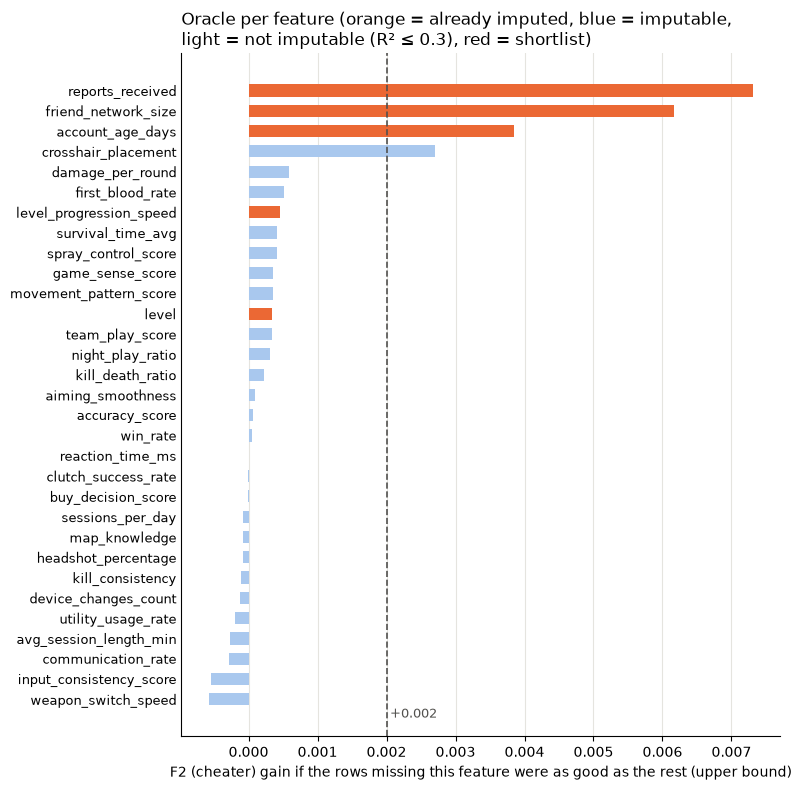

In [14]:
t = table.sort_values('ΔF2')
fig, ax = plt.subplots(figsize=(8, 8))
colours = [RED if s else ORANGE if i == 'yes' else BLUE if imp else '#a9c8ee'
           for s, i, imp in zip(t['shortlist'], t['imputed'], t['imputable'])]
ax.barh(t.index, t['ΔF2'], height=0.6, color=colours)
ax.axvline(0.002, color=INK, linestyle='--', linewidth=1.2)
ax.text(0.00205, -0.9, '+0.002', fontsize=9, color=INK)
ax.set_xlabel('F2 (cheater) gain if the rows missing this feature were as good as the rest (upper bound)')
ax.set_title('Oracle per feature (orange = already imputed, blue = imputable,\nlight = not imputable (R² ≤ 0.3), red = shortlist)', loc='left')
ax.tick_params(axis='y', length=0, labelsize=9)
tidy(ax, 'x')
plt.tight_layout()
plt.show()

**NOTE:**


The shortlist is empty. The 4 features with a real gap are either already imputed (`reports_received`, `friend_network_size`, `account_age_days`) or not imputable (`crosshair_placement`, R² 0.01).

The oracle in F2 (cheater) is smaller than it was in macro F2 (+0.011), but it is still clear for the imputed features: `reports_received` +0.0073, `friend_network_size` +0.0062, `account_age_days` +0.0038, `crosshair_placement` +0.0027. Retuning the threshold changes these by at most 0.0001. Their gap remains after imputation, because an imputed value is pulled toward the middle and rarely lands in the range that settles the label. Imputable features without a gap (`level_progression_speed`, the aim block) have an oracle of at most +0.0005.

If every row scored like rows with 0–1 missing, F2 (cheater) would rise by +0.0172 (+0.0185 with a retuned threshold). That is the full missingness ceiling (it was +0.024 in macro F2), but imputation from the other features cannot recover it, because the information is not in them.

### 5b. Can `level` and `level_progression_speed` bound a missing `account_age_days`?

แบบ Task 3 ที่ feature หนึ่งคำนวณจากอีกตัวได้: ถ้า `level_progression_speed` = level / age × u แล้ว u อยู่ในช่วงแคบ ตอน age ว่างก็จะรู้ขอบเขตของ age ได้ และกฎ "age > 1,000 ⇒ ผู้เล่นปกติ" (หรือ age < 15 ⇒ ผู้เล่นปกติ) อาจตัดสินได้เลย ดูว่ามีกี่แถว และโมเดลตอนนี้ทายแถวพวกนั้นถูกอยู่แล้วหรือเปล่า

In [15]:
u = (tr['level_progression_speed'] * tr['account_age_days'] / tr['level']).dropna()  # speed = level / age * u
print(f"u = speed * age / level: min {u.min():.3f}, 1% {u.quantile(0.01):.3f}, median {u.median():.3f}, 99% {u.quantile(0.99):.3f}, max {u.max():.3f} "
      f"| mean legit {u[y[u.index] == 0].mean():.3f}, cheaters {u[y[u.index] == 1].mean():.3f}")
age_gone = tr['account_age_days'].isna() & tr['level'].notna() & tr['level_progression_speed'].notna()
low_bound = u.min() * tr['level'] / tr['level_progression_speed']   # smallest age the other two allow
high_bound = u.max() * tr['level'] / tr['level_progression_speed']  # largest age they allow
rows = []
for name, sel in (('age missing, lower bound > 1,000', age_gone & (low_bound > 1000)),
                  ('age missing, upper bound < 15', age_gone & (high_bound < 15))):
    sel = sel.to_numpy()
    rows.append({'rows': name, 'count': int(sel.sum()), 'cheater share': y[sel].mean(), 'model says cheater': pred[sel].mean(),
                 'rows the model gets wrong': int((pred[sel] != y[sel]).sum())})
print(f"rows missing age: {tr['account_age_days'].isna().sum():,}, of which level and speed are both present: {age_gone.sum():,}")
pd.DataFrame(rows).set_index('rows').style.format({'count': '{:,}', 'cheater share': '{:.1%}', 'model says cheater': '{:.1%}'})

u = speed * age / level: min 0.150, 1% 0.159, median 0.616, 99% 1.071, max 1.080 | mean legit 0.615, cheaters 0.616
rows missing age: 13,141, of which level and speed are both present: 11,199


,count,cheater share,model says cheater,rows the model gets wrong
rows,,,,
"age missing, lower bound > 1,000",24,0.0%,33.3%,8
"age missing, upper bound < 15",114,0.0%,7.0%,8


การเติมค่าเฉลี่ยดึงค่าเข้าหาตรงกลาง จึงไม่ค่อยตกในช่วงที่กฎตัดสินได้ ทางเลือกคือทาย**ความน่าจะเป็นที่ค่าที่ว่างจะข้ามขอบของกฎ** (label-free classifier บนแถวที่มีค่า, 3-fold) ถ้ามีแถวที่ทายได้มั่นใจ (P > 0.9) เยอะ ก็อาจเป็นฟีเจอร์ใหม่ได้

ใช้ขอบทุกด้านจากตารางช่วงค่าใน README (12 กฎ รวม `account_age_days < 15`, `friend_network_size < 10`, `level_progression_speed < 0.004` ที่ `pis/task1_features.py` ไม่ได้ใช้) `cheater share when it fires` เช็คว่ากฎตัดสินได้จริง (0% หรือ 100%) แล้วดูแถวที่ค่าว่างจริงด้วย: เทรนบนแถวที่มีค่าทั้งหมด ทายแถวที่ว่าง นับแถวที่ P > 0.9, แถวที่โมเดลตอนนี้ทายผิดในกลุ่มนั้น และ F2 (คนโกง) ที่เปลี่ยนถ้าบังคับแถวกลุ่มนั้นเป็นคลาสของกฎ (ขอบบนของสิ่งที่ฟีเจอร์ใหม่จะให้ได้)

In [16]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import cross_val_predict

# Every one-sided boundary in the README range table (legit range vs cheater range):
#   crosshair 0.82-0.96 / 0.80-0.94, reports 5-29 / 4-19, level 28-100 / 25-96,
#   age 1-1500 / 15-1000, friends 0-349 / 10-269, progression speed 0.003-80 / 0.004-6.25
RULES = [('crosshair_placement', '<', 0.82, 'cheater'), ('crosshair_placement', '>', 0.94, 'legit'),
         ('reports_received', '<', 5, 'cheater'), ('reports_received', '>', 19, 'legit'),
         ('level', '<', 28, 'cheater'), ('level', '>', 96, 'legit'),
         ('account_age_days', '<', 15, 'legit'), ('account_age_days', '>', 1000, 'legit'),
         ('friend_network_size', '<', 10, 'legit'), ('friend_network_size', '>', 269, 'legit'),
         ('level_progression_speed', '<', 0.004, 'legit'), ('level_progression_speed', '>', 6.26, 'legit')]
rule_rows = []
for f, side, v, settles in RULES:
    present = tr[f].notna()
    X = tr.loc[present, [c for c in feats if c != f]]  # other features only, never the label
    crosses = (tr.loc[present, f] < v) if side == '<' else (tr.loc[present, f] > v)
    pr = cross_val_predict(HistGradientBoostingClassifier(random_state=342), X, crosses, cv=3, method='predict_proba')[:, 1]
    sure = pr > 0.9
    # Rows where the value is missing: fit on all present rows (label-free), flag P > 0.9 and
    # see what forcing those rows to the rule's class would do to the OOF.
    gone = np.flatnonzero(~present.to_numpy())
    q = HistGradientBoostingClassifier(random_state=342).fit(X, crosses).predict_proba(tr.loc[~present, X.columns])[:, 1]
    flagged = gone[q > 0.9]
    forced = pred.copy()
    forced[flagged] = 1 if settles == 'cheater' else 0
    rule_rows.append({'rule': f"{f} {side} {v}", 'settles': settles,
                      'cheater share when it fires': y[present.to_numpy()][crosses.to_numpy()].mean(),
                      'rows crossing (present rows)': crosses.mean(), 'AUC': roc_auc_score(crosses, pr),
                      'rows with P > 0.9': int(sure.sum()), 'precision at P > 0.9': crosses[sure].mean() if sure.any() else np.nan,
                      'gap significant (section 2)': by_feat.loc[f, 'sig_auc'] == 'worse',
                      'missing rows with P > 0.9': len(flagged), 'model wrong there': int((pred[flagged] != y[flagged]).sum()),
                      'ΔF2 if forced': fbeta_score(y, forced, beta=2) - f2_all})
(pd.DataFrame(rule_rows).set_index('rule').style
    .format({'cheater share when it fires': '{:.1%}', 'rows crossing (present rows)': '{:.1%}', 'AUC': '{:.3f}',
             'rows with P > 0.9': '{:,}', 'precision at P > 0.9': '{:.2f}', 'missing rows with P > 0.9': '{:,}',
             'ΔF2 if forced': '{:+.5f}'}, na_rep='–')
    .set_caption('Label-free: can the other features tell that a hidden value crosses a rule boundary?'))

,settles,cheater share when it fires,rows crossing (present rows),AUC,rows with P > 0.9,precision at P > 0.9,gap significant (section 2),missing rows with P > 0.9,model wrong there,ΔF2 if forced
rule,,,,,,,,,,
crosshair_placement < 0.82,cheater,100.0%,5.0%,0.713,0,–,True,0,0,+0.00000
crosshair_placement > 0.94,legit,0.0%,9.3%,0.613,0,–,True,0,0,+0.00000
reports_received < 5,cheater,100.0%,2.1%,0.690,0,–,True,0,0,+0.00000
reports_received > 19,legit,0.0%,10.7%,0.873,0,–,True,0,0,+0.00000
level < 28,cheater,100.0%,1.4%,0.833,0,–,False,0,0,+0.00000
level > 96,legit,0.0%,3.6%,0.715,0,–,False,0,0,+0.00000
account_age_days < 15,legit,0.0%,1.9%,0.990,825,0.95,True,143,16,+0.00007
account_age_days > 1000,legit,0.0%,7.3%,0.921,11,1.00,True,4,1,+0.00000
friend_network_size < 10,legit,0.0%,2.9%,0.931,0,–,True,0,0,+0.00000


threshold ที่ต่ำลง (ทายคนโกงมากขึ้น) อาจทำให้แถวที่กฎตัดสินแล้วว่าเป็นผู้เล่นปกติ ถูกทายเป็นคนโกงบ่อยขึ้น นับแถวที่ค่าที่**มีอยู่** หรือ**ขอบเขตของ age** (แถวที่ age ว่าง) ตัดสิน label ได้แน่นอน แยกเป็นกฎที่ `pis/task1_features.py` ใช้อยู่ (โมเดลเห็นเป็นฟีเจอร์แล้ว) กับกฎที่ยังไม่ได้ใช้ แล้วดูว่าโมเดลทายผิดกี่แถว และ F2 (คนโกง) จะเปลี่ยนเท่าไรถ้าบังคับแถวเหล่านั้นตามกฎ (กฎไม่ใช้ label, เป็นขอบบนของการเพิ่มกฎ)

In [17]:
def fires(rules):
    m = np.zeros(len(tr), bool)
    for f, side, v, _ in rules:
        m |= (tr[f] < v).to_numpy() if side == '<' else (tr[f] > v).to_numpy()  # NaN never fires
    return m


in_pipeline = [r for r in RULES if (r[3] == 'legit' and r[1] == '>') or r[3] == 'cheater']  # LEGIT_FLOOR / CHEAT_CEILING
not_in_pipeline = [r for r in RULES if r not in in_pipeline]
settled = {
    'legit: rules the pipeline uses': (fires([r for r in in_pipeline if r[3] == 'legit']), 0),
    'legit: lower-bound rules (age < 15, friends < 10, speed < 0.004)': (fires(not_in_pipeline), 0),
    'legit: age missing, bound from level and speed': ((age_gone & ((low_bound > 1000) | (high_bound < 15))).to_numpy(), 0),
    'cheater: rules the pipeline uses': (fires([r for r in in_pipeline if r[3] == 'cheater']), 1),
}
rows, forced_all = [], pred.copy()
for name, (m, cls) in settled.items():
    forced = pred.copy(); forced[m] = cls; forced_all[m] = cls
    rows.append({'rows settled by': name, 'rows': int(m.sum()), 'cheater share': y[m].mean(),
                 'model wrong (at threshold)': int((pred[m] != cls).sum()), 'ΔF2 if forced': fbeta_score(y, forced, beta=2) - f2_all})
legit_any = np.any([m for m, cls in settled.values() if cls == 0], axis=0)
cheat_any = settled['cheater: rules the pipeline uses'][0]
assert not (legit_any & cheat_any).any(), 'a row is settled both ways'
rows.append({'rows settled by': 'all of the above', 'rows': int((legit_any | cheat_any).sum()), 'cheater share': y[legit_any | cheat_any].mean(),
             'model wrong (at threshold)': int((pred[legit_any] == 1).sum() + (pred[cheat_any] == 0).sum()),
             'ΔF2 if forced': fbeta_score(y, forced_all, beta=2) - f2_all})
(pd.DataFrame(rows).set_index('rows settled by').style
    .format({'rows': '{:,}', 'cheater share': '{:.1%}', 'model wrong (at threshold)': '{:,}', 'ΔF2 if forced': '{:+.5f}'})
    .set_caption(f'Rows a known value settles, predictions at threshold {threshold:.3f}'))

,rows,cheater share,model wrong (at threshold),ΔF2 if forced
rows settled by,,,,
legit: rules the pipeline uses,"22,491",0.0%,0,+0.00000
"legit: lower-bound rules (age < 15, friends < 10, speed < 0.004)","3,253",0.0%,13,+0.00006
"legit: age missing, bound from level and speed",138,0.0%,16,+0.00007
cheater: rules the pipeline uses,"6,236",100.0%,0,+0.00000
all of the above,"30,155",20.7%,29,+0.00013


**NOTE:**


The data fit speed = level / age × u with u spread evenly over [0.15, 1.08], the same in both classes. So level and speed bound a missing age, but the band is 7× wide. Only 138 of 11,199 such rows fall entirely beyond a rule boundary (all legit). At the new threshold the model calls 16 of them cheaters (8 of the 24 with lower bound > 1,000, 8 of the 114 with upper bound < 15), against 4 at the macro-F2 threshold.

The rule table covers all 12 one-sided boundaries in the README. Each one settles the label exactly (cheater share 0% or 100% when it fires).
- `account_age_days` < 15: AUC 0.990, 825 present rows with P > 0.9 at precision 0.95. On the age-missing rows, 143 reach P > 0.9 (all legit) and the model now gets 16 wrong (6 before). Forcing them to legit gains +0.00007 F2.
- `friend_network_size` < 10: AUC 0.931, but no row reaches P > 0.9. `friend_network_size` has a significant gap in section 2, but this rule does not help there.
- `level_progression_speed` < 0.004 fires on only 8 rows, too few to learn (AUC 0.23 is noise). The other rules stay moderate (AUC 0.61–0.92) and are almost never confident.

As expected, the lower threshold does call more settled-legit rows cheaters, but only a few. The rules the pipeline already encodes (`n_sure_legit_rules`, `n_sure_cheat_rules`) are followed perfectly: 22,491 settled-legit and 6,236 settled-cheater rows, 0 wrong. The rules the pipeline does not use (age < 15, friends < 10, speed < 0.004) settle 3,253 rows and the model gets 13 wrong. The age bound adds 16 more. Forcing all 29 to their rule's class gains +0.00013 F2, far below +0.002. A label-free rule-override step is not worth an experiment.

## Summary

- **Metric:** F2 ของคลาสคนโกง (ตามที่ Kaggle ใช้) ด้วย threshold ของ pipeline (commit 080d9a0) บน OOF 3-fold: threshold 0.380 → **0.1805**, F2 (คนโกง) **0.8381** (macro F2 ที่ threshold นี้ 0.7165) AUC 0.8922 ไม่เปลี่ยน (ต่างจาก README 0.8926 เพราะสภาพแวดล้อม)
- **ค่าว่าง:** แถวครบมีแค่ 1.8% เฉลี่ยว่าง 3.7 ช่องต่อแถว คะแนนตกตามจำนวนช่องที่ว่าง (AUC 0.919 → 0.847, F2 0.862 → 0.819 จาก 0 ถึง 8 ช่อง) สัดส่วนคนโกงเท่ากันทุกกลุ่ม การว่างจึงไม่บอก label
- **Threshold ต่อกลุ่ม (1b):** threshold ที่ดีที่สุดของแต่ละกลุ่มอยู่ที่ 0.159–0.186 ใกล้กับค่าเดียว 0.181 วัดแบบเลือกบน 2 fold วัดบน fold ที่ 3 ได้ +0.0004 จึงใช้ threshold เดียวต่อไป
- **Gap ต่อ feature:** significant (Bonferroni) 4 ตัวเดิม คือ `reports_received`, `friend_network_size`, `account_age_days`, `crosshair_placement` (AUC z −12 ถึง −21, F2 z −5.6 ถึง −11.9) ทั้ง 4 ตัวเป็น feature ของกฎช่วงค่า ส่วน 25 ตัวที่เหลือว่างแล้วไม่เสียอะไร
- **เติมค่า:** เติมได้แค่บล็อกประวัติบัญชี (R² บนค่าจริง / log1p: age 0.71 / 0.87, progression speed 0.63 / 0.81, friends 0.50 / 0.63) ซึ่ง pipeline เติมอยู่แล้ว `crosshair_placement` เติมไม่ได้ (R² 0.01) ไม่มี feature ไหนข้ามเส้น 0.3 เมื่อใช้ log1p
- **บล็อก:** มี 2 บล็อก (ประวัติบัญชี, การเล็ง) จาก 465 คู่มีแค่ 8 คู่ที่ |ρ| ≥ 0.2
- **Oracle:** ต่อ feature สูงสุด +0.0073 F2 (`reports_received` ที่เติมแล้ว แต่ R² แค่ 0.21) ถ้าทุกแถวดีเท่าแถวที่ว่าง ≤ 1 ช่อง ได้ +0.0172 (+0.0185 ถ้าเลือก threshold ใหม่) นี่คือขนาดของเพดาน แต่ข้อมูลที่หายไม่ได้อยู่ใน feature อื่น
- **ลองเพิ่ม (5b):** threshold ที่ต่ำลงทำให้โมเดลทายแถวที่กฎตัดสินว่าเป็นผู้เล่นปกติผิดมากขึ้นนิดหน่อย กฎที่ pipeline ใช้อยู่ถูกครบ (28,727 แถว ผิด 0) ส่วนกฎขอบล่างที่ยังไม่ได้ใช้ (age < 15, friends < 10, speed < 0.004) และขอบเขตของ age รวมผิด 29 แถว ถ้าบังคับตามกฎทั้งหมดได้แค่ +0.00013 `account_age_days < 15` ทายจาก feature อื่นได้ดี (AUC 0.990) แต่ในแถวที่ age ว่างช่วยได้แค่ +0.00007

**Decision: ไม่มีการทดลองเติมค่าเพิ่มสำหรับ Task 1 (เหมือนเดิม)**

| เกณฑ์ | ผล | ผ่านไหม |
|---|---|---|
| OOF แย่ลงจริงในแถวที่ feature ว่าง (Bonferroni) | 4 feature | ผ่าน |
| เติมค่าได้ (R² > 0.3) และยังไม่ได้เติม | ไม่มี: 3 ตัวเติมแล้ว, `reports_received` 0.21, `crosshair_placement` 0.01 | ไม่ผ่าน |
| oracle ของ shortlist > +0.002 F2 (คนโกง) | shortlist ว่าง | – |
| ตรวจเพิ่ม: บังคับแถวที่กฎตัดสินแล้ว | +0.00013 | ไม่ถึง +0.002 |
| ตรวจเพิ่ม: threshold ต่อกลุ่มจำนวนช่องที่ว่าง | +0.0004 (honest) | ไม่ถึง +0.002 |

เปลี่ยนมาใช้ metric ของ Kaggle แล้วข้อสรุปไม่เปลี่ยน ค่าว่างเป็นเพดานจริง (+0.017 F2 ถ้าไม่มีค่าว่าง) แต่ส่วนที่เติมจาก feature อื่นได้ pipeline ทำไปแล้ว ที่เหลือคือข้อมูลที่หายไปจริงๆ: feature ที่มีผลที่สุดสัมพันธ์กับตัวอื่นน้อย (`reports_received` R² 0.21, `crosshair_placement` 0.01) ส่วน age ที่เติมได้ดีที่สุดก็ยังมีสัญญาณรบกวนแบบคูณ (u กว้าง 7 เท่า) ต่างจาก Task 3 ที่ feature เกือบเป็นสำเนาของกัน (R² 0.995) จึงไม่ควรลงแรงเรื่องค่าว่างใน Task 1 ต่อ